In [ ]:
import pandas as pd
import os
import numpy as np

for i in range(1,8):
    attr= np.load(f"/scratch/data/PUR_DATA/test/Region_{i}/daymet_19800101_20141231_attr_671.npy")

    forcing= np.load(f"/scratch/data/PUR_DATA/test/Region_{i}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
    gaugeid= forcing[:,0,14]



array([12010000., 12013500., 12020000., 12025700., 12035000., 12040500.,
       12041200., 12048000., 12054000., 12056500., 12073500., 12082500.,
       12092000., 12114500., 12115000., 12117000., 12143600., 12144000.,
       12145500., 12147500., 12167000., 12175500., 12178100., 12186000.,
       12189500., 12375900., 12377150., 12381400., 12383500., 12390700.,
       12411000., 12447390., 12451000., 12488500., 13011500., 13011900.,
       13018300., 13023000., 13161500., 13235000., 13240000., 13313000.,
       13331500., 14020000., 14096850., 14137000., 14138800., 14138870.,
       14138900., 14139800., 14141500., 14154500., 14158790., 14166500.,
       14182500., 14185000., 14185900., 14187000., 14216500., 14222500.,
       14236200., 14301000., 14303200., 14305500., 14306340., 14306500.,
       14308990., 14309500., 14316700., 14325000., 14362250., 14400000.])

In [5]:
## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

loss= 'NSE'
losses= ['RMSE', 'NSE']

method= 'Eckhardt'
methods= ['Furey', 'Eckhardt', 'LocalHYSEP']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
# model= 'HBV'
models= ['HBV', 'marrmot_PRMS', 'HBV_capillary']

# if model=='HBV':
#     dyn= 'parBETA_parBETAET_'

# if model=='marrmot_PRMS':
#     dyn= 'alpha_cgw_scx_tt_'

# if model=='HBV_capillary':
#     dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    n=11
if test== 'PUR':
    n=8

    
import numpy as np
import os

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den



models= ['HBV', 'HBV_capillary', 'marrmot_PRMS']
# models= ['HBV', 'marrmot_PRMS']

for k in range(len(models)):
    model= models[k]

    if model=='HBV':
        dyn= 'parBETA_parBETAET_'

    if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

    if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'


# ============================================================
# Containers
# ============================================================

    metrics_old = {
        "NSE": [],
        "NSEbase": []
    }

    metrics_new = {
        "NSE": [],
        "NSEbase": []
    }

    # ============================================================
    # Loop over folds
    # ============================================================

    for i in range(1, n):
        attr= np.load(f"/scratch/data/PUR_DATA/test/Region_{i}/daymet_19800101_20141231_attr_671.npy")
        
        forcing= np.load(f"/scratch/data/PUR_DATA/test/Region_{i}/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
        

        if test== 'PUB':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/{method}_{objectives[1]}/{i}/"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/OUTPUTS_PUB_{objectives[0]}/{i}/"
 

        if test== 'PUR':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/{method}_{objectives[1]}/{loss}/{model}/Region_{i}/"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_{objectives[0]}/Region_{i}/"

        obs_flow = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy")
        )

        sim_old = np.load(
            f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_{i}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")

        

        sim_new = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
        )


        obs_baseflow = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/baseflow.npy")
        )

        gw_old = np.load(
            f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_{i}/LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")

        

        gw_new = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/gwflow.npy")
        )

        gw_old = np.squeeze(gw_old)
        gw_new = np.squeeze(gw_new)
        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)
        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        for k in range(obs_baseflow.shape[1]):
            gaugeid= forcing[i,0,14]

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]
            obsbase = obs_baseflow[:, k]
            oldg = gw_old[:, k]
            newg = gw_new[:, k]
            # =====================================================
            # Overall metrics
            # =====================================================
            metrics_old["NSEbase"].append(calc_nse(obsbase, oldg))
            metrics_new["NSEbase"].append(calc_nse(obsbase, newg))
            metrics_old["NSE"].append(calc_nse(obs, old))
            metrics_new["NSE"].append(calc_nse(obs, new))
    # ============================================================
    # Print comparison
    # ============================================================
    metric_order = [ 'NSE', "NSEbase"]
    print("=" * 60)
    print(model)
    print("=" * 60)
    for metric in metric_order:
        
        old = np.nanmedian(metrics_old[metric])
        new = np.nanmedian(metrics_new[metric])
        print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

    print("=" * 60)

HBV
NSE          :   0.6331 →   0.6472
NSEbase      :   0.4486 →   0.6417
HBV_capillary
NSE          :   0.6214 →   0.6327
NSEbase      :   0.3799 →   0.6263
marrmot_PRMS
NSE          :   0.6223 →   0.6209
NSEbase      :   0.3339 →   0.6464


In [10]:
import os
import numpy as np
import pandas as pd
method='LocalHYSEP'
test= 'PUR'

models = ['HBV', 'HBV_capillary', 'marrmot_PRMS']

# Store all 3 model DataFrames
model_dfs = {}

for model in models:

    # ============================================================
    # Dynamic parameter folder
    # ============================================================
    if model == 'HBV':
        dyn = 'parBETA_parBETAET_'

    elif model == 'marrmot_PRMS':
        dyn = 'alpha_cgw_scx_tt_'

    elif model == 'HBV_capillary':
        dyn = 'parBETA_parBETAET_parK0_parUZL_'

    # ============================================================
    # Container for this model
    # ============================================================
    rows = []

    # ============================================================
    # Loop over PUR regions
    # ============================================================
    for i in range(1, 8):

        attr = np.load(
            f"/scratch/data/PUR_DATA/test/Region_{i}/"
            f"daymet_19800101_20141231_attr_671.npy"
        )

        forcing = np.load(
            f"/scratch/data/PUR_DATA/test/Region_{i}/"
            f"daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
        )

        # ========================================================
        # Folders
        # ========================================================
        if test == 'PUB':

            folder = (
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/"
                f"{method}_{objectives[1]}/{i}/"
            )

            sfolder = (
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUB/"
                f"OUTPUTS_PUB_{objectives[0]}/{i}/"
            )

        elif test == 'PUR':

            folder = (
                f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/"
                f"{method}_{objectives[1]}/{loss}/{model}/Region_{i}/"
            )

            sfolder = (
                f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/"
                f"OUTPUTS_PUR_{objectives[0]}/Region_{i}/"
            )

        # ========================================================
        # Common experiment folder
        # ========================================================
        exp_folder = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
            f"{dyn}/ts1989_1999/"
        )

        # ========================================================
        # Observations
        # ========================================================
        obs_flow = np.load(
            os.path.join(
                folder,
                exp_folder,
                "00060_Mean.npy"
            )
        )

        obs_baseflow = np.load(
            os.path.join(
                folder,
                exp_folder,
                "baseflow.npy"
            )
        )

        # ========================================================
        # Single-objective simulations
        # ========================================================
        sim_old = np.load(
            f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/"
            f"OUTPUTS_PUR_Single/Region_{i}/"
            f"{exp_folder}flow_sim.npy"
        )

        gw_old = np.load(
            f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/"
            f"OUTPUTS_PUR_Single/Region_{i}/"
            f"{exp_folder}gwflow.npy"
        )

        # ========================================================
        # Multi-objective simulations
        # ========================================================
        sim_new = np.load(
            os.path.join(
                folder,
                exp_folder,
                "flow_sim.npy"
            )
        )

        gw_new = np.load(
            os.path.join(
                folder,
                exp_folder,
                "gwflow.npy"
            )
        )

        # ========================================================
        # Remove unnecessary dimensions
        # ========================================================
        obs_flow = np.squeeze(obs_flow)
        obs_baseflow = np.squeeze(obs_baseflow)

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        gw_old = np.squeeze(gw_old)
        gw_new = np.squeeze(gw_new)

        # ========================================================
        # Check basin count
        # ========================================================
        n_basins = obs_baseflow.shape[1]

        print(
            f"{model} | Region {i} | "
            f"Basins = {n_basins} | "
            f"attr shape = {attr.shape}"
        )

        # ========================================================
        # Loop over basins
        # ========================================================
        for k in range(n_basins):

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]

            obsbase = obs_baseflow[:, k]
            oldg = gw_old[:, k]
            newg = gw_new[:, k]

            # ====================================================
            # Calculate NSE
            # ====================================================
            nse_flow_single = calc_nse(obs, old)
            nse_flow_multi = calc_nse(obs, new)

            nse_base_single = calc_nse(obsbase, oldg)
            nse_base_multi = calc_nse(obsbase, newg)

            # ====================================================
            # Create row
            # ====================================================

            # First add useful identifiers
            row = {
                "Model": model,
                "Region": i,
            }

            # ----------------------------------------------------
            # Gauge ID
            # ----------------------------------------------------
            # Assuming forcing shape is:
            # (basins, time, variables)
            #
            # If gauge ID is stored elsewhere, modify this line.
            row["GAGE_ID"] = forcing[k, 0, 14]

            # ----------------------------------------------------
            # Add all 35 attributes
            # ----------------------------------------------------
            for j in range(attr.shape[1]):
                row[f"Attr_{j+1}"] = attr[k, j]

            # ----------------------------------------------------
            # Add NSE metrics
            # ----------------------------------------------------
            row["NSE_Flow_Single"] = nse_flow_single
            row["NSE_Flow_Multi"] = nse_flow_multi

            row["NSE_Baseflow_Single"] = nse_base_single
            row["NSE_Baseflow_Multi"] = nse_base_multi

            # Optional differences
            row["NSE_Delta_Flow"] = (
                nse_flow_multi - nse_flow_single
            )

            row["NSE_Delta_Baseflow"] = (
                nse_base_multi - nse_base_single
            )

            rows.append(row)

    # ============================================================
    # Convert this model to DataFrame
    # ============================================================
    df_model = pd.DataFrame(rows)


    df_model.to_csv(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/RF/RandomForest_{method}_{model}.csv", index=False)

    # Store in dictionary
    model_dfs[model] = df_model

    print("\n" + "=" * 70)
    print(model)
    print(df_model.shape)
    print("=" * 70)

    display(df_model.head())

HBV | Region 1 | Basins = 92 | attr shape = (92, 35)
HBV | Region 2 | Basins = 95 | attr shape = (95, 35)
HBV | Region 3 | Basins = 93 | attr shape = (93, 35)
HBV | Region 4 | Basins = 51 | attr shape = (51, 35)
HBV | Region 5 | Basins = 68 | attr shape = (68, 35)
HBV | Region 6 | Basins = 60 | attr shape = (60, 35)
HBV | Region 7 | Basins = 72 | attr shape = (72, 35)

HBV
(531, 44)


,Model,Region,GAGE_ID,Attr_1,Attr_2,Attr_3,Attr_4,Attr_5,Attr_6,Attr_7,...,Attr_32,Attr_33,Attr_34,Attr_35,NSE_Flow_Single,NSE_Flow_Multi,NSE_Baseflow_Single,NSE_Baseflow_Multi,NSE_Delta_Flow,NSE_Delta_Baseflow
0,HBV,1,1022500.0,3.608126,2.119256,-0.114530,0.245259,0.587356,20.55,1.205279,...,0.164618,0.000000,0.0710,-14.2138,0.692698,0.687341,0.591390,0.608140,-0.005357,0.016750
1,HBV,1,1031500.0,3.522957,2.071324,0.104091,0.291836,0.587950,18.90,1.148936,...,0.443863,0.026258,0.0747,-14.8410,0.737735,0.671704,0.609332,0.609327,-0.066030,-0.000005
2,HBV,1,1047000.0,3.323146,2.090024,0.147776,0.280118,0.628929,20.10,1.165217,...,0.288613,0.000000,0.0522,-14.4819,0.537061,0.426361,0.570797,0.354317,-0.110700,-0.216480
3,HBV,1,1052500.0,3.730858,2.096423,0.152097,0.352698,0.561914,13.50,1.129707,...,0.374062,0.000000,0.0711,-15.1658,0.720647,0.698663,0.585585,0.734160,-0.021984,0.148574
4,HBV,1,1054200.0,4.067132,2.128355,0.104960,0.299642,0.523306,17.50,1.194539,...,0.104295,0.000000,0.0288,-14.2147,0.526196,0.514973,0.619435,0.520130,-0.011223,-0.099306


HBV_capillary | Region 1 | Basins = 92 | attr shape = (92, 35)
HBV_capillary | Region 2 | Basins = 95 | attr shape = (95, 35)
HBV_capillary | Region 3 | Basins = 93 | attr shape = (93, 35)
HBV_capillary | Region 4 | Basins = 51 | attr shape = (51, 35)
HBV_capillary | Region 5 | Basins = 68 | attr shape = (68, 35)
HBV_capillary | Region 6 | Basins = 60 | attr shape = (60, 35)
HBV_capillary | Region 7 | Basins = 72 | attr shape = (72, 35)

HBV_capillary
(531, 44)


,Model,Region,GAGE_ID,Attr_1,Attr_2,Attr_3,Attr_4,Attr_5,Attr_6,Attr_7,...,Attr_32,Attr_33,Attr_34,Attr_35,NSE_Flow_Single,NSE_Flow_Multi,NSE_Baseflow_Single,NSE_Baseflow_Multi,NSE_Delta_Flow,NSE_Delta_Baseflow
0,HBV_capillary,1,1022500.0,3.608126,2.119256,-0.114530,0.245259,0.587356,20.55,1.205279,...,0.164618,0.000000,0.0710,-14.2138,0.663748,0.727940,0.523663,0.685195,0.064192,0.161532
1,HBV_capillary,1,1031500.0,3.522957,2.071324,0.104091,0.291836,0.587950,18.90,1.148936,...,0.443863,0.026258,0.0747,-14.8410,0.661485,0.727728,0.323076,0.650897,0.066243,0.327821
2,HBV_capillary,1,1047000.0,3.323146,2.090024,0.147776,0.280118,0.628929,20.10,1.165217,...,0.288613,0.000000,0.0522,-14.4819,0.465940,0.445757,0.347470,0.445817,-0.020182,0.098347
3,HBV_capillary,1,1052500.0,3.730858,2.096423,0.152097,0.352698,0.561914,13.50,1.129707,...,0.374062,0.000000,0.0711,-15.1658,0.760935,0.657769,0.276404,0.697333,-0.103166,0.420929
4,HBV_capillary,1,1054200.0,4.067132,2.128355,0.104960,0.299642,0.523306,17.50,1.194539,...,0.104295,0.000000,0.0288,-14.2147,0.476855,0.506250,0.401909,0.516610,0.029396,0.114700


marrmot_PRMS | Region 1 | Basins = 92 | attr shape = (92, 35)
marrmot_PRMS | Region 2 | Basins = 95 | attr shape = (95, 35)
marrmot_PRMS | Region 3 | Basins = 93 | attr shape = (93, 35)
marrmot_PRMS | Region 4 | Basins = 51 | attr shape = (51, 35)
marrmot_PRMS | Region 5 | Basins = 68 | attr shape = (68, 35)
marrmot_PRMS | Region 6 | Basins = 60 | attr shape = (60, 35)
marrmot_PRMS | Region 7 | Basins = 72 | attr shape = (72, 35)

marrmot_PRMS
(531, 44)


,Model,Region,GAGE_ID,Attr_1,Attr_2,Attr_3,Attr_4,Attr_5,Attr_6,Attr_7,...,Attr_32,Attr_33,Attr_34,Attr_35,NSE_Flow_Single,NSE_Flow_Multi,NSE_Baseflow_Single,NSE_Baseflow_Multi,NSE_Delta_Flow,NSE_Delta_Baseflow
0,marrmot_PRMS,1,1022500.0,3.608126,2.119256,-0.114530,0.245259,0.587356,20.55,1.205279,...,0.164618,0.000000,0.0710,-14.2138,0.726306,0.617054,0.472142,0.513290,-0.109251,0.041148
1,marrmot_PRMS,1,1031500.0,3.522957,2.071324,0.104091,0.291836,0.587950,18.90,1.148936,...,0.443863,0.026258,0.0747,-14.8410,0.727486,0.475634,0.382277,0.370638,-0.251852,-0.011639
2,marrmot_PRMS,1,1047000.0,3.323146,2.090024,0.147776,0.280118,0.628929,20.10,1.165217,...,0.288613,0.000000,0.0522,-14.4819,0.613158,0.367954,0.428551,0.339472,-0.245204,-0.089080
3,marrmot_PRMS,1,1052500.0,3.730858,2.096423,0.152097,0.352698,0.561914,13.50,1.129707,...,0.374062,0.000000,0.0711,-15.1658,0.658161,0.468009,0.478355,0.534449,-0.190152,0.056094
4,marrmot_PRMS,1,1054200.0,4.067132,2.128355,0.104960,0.299642,0.523306,17.50,1.194539,...,0.104295,0.000000,0.0288,-14.2147,0.442233,0.408903,0.305223,0.292713,-0.033330,-0.012510


In [ ]:
import pandas as pd
method= 'Eckhardt'
hydromodel= 'HBV'
df= pd.read_csv(f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/RF/RandomForest_{method}_{hydromodel}.csv")
df
attrnames= [
  "p_mean",
  "pet_mean",
  "p_seasonality",
  "frac_snow",
  "aridity",
  "high_prec_freq",
  "high_prec_dur",
  "low_prec_freq",
  "low_prec_dur",
  "elev_mean",
  "slope_mean",
  "area_gages2",
  "frac_forest",
  "lai_max",
  "lai_diff",
  "gvf_max",
  "gvf_diff",
  "dom_land_cover_frac",
  "dom_land_cover",
  "root_depth_50",
  "soil_depth_pelletier",
  "soil_depth_statsgo",
  "soil_porosity",
  "soil_conductivity",
  "max_water_content",
  "sand_frac",
  "silt_frac",
  "clay_frac",
  "geol_1st_class",
  "glim_1st_class_frac",
  "geol_2nd_class",
  "glim_2nd_class_frac",
  "carbonate_rocks_frac",
  "geol_porostiy",
  "geol_permeability"
]


for i in range(35):
    df.rename(columns={f"Attr_{i+1}":attrnames[i]},inplace=True)

df.drop(columns={'Model', 'Region', 'GAGE_ID','NSE_Flow_Single', 'NSE_Flow_Multi',
       'NSE_Baseflow_Single', 'NSE_Baseflow_Multi', 'NSE_Delta_Flow', 
       "p_mean",
         "pet_mean",
         "p_seasonality",
        #  "frac_snow",
        #  "aridity",
         "high_prec_freq",
         "high_prec_dur",
         "low_prec_freq",
         "low_prec_dur",
        #  "elev_mean",
        #  "slope_mean",
         "area_gages2",
         "frac_forest",
         "lai_max",
        #  "lai_diff",
         "gvf_max",
        #  "gvf_diff",
        #  "dom_land_cover_frac",
         "dom_land_cover",
         "root_depth_50",
        #  "soil_depth_pelletier",
        #  "soil_depth_statsgo",
         "soil_porosity",
         "soil_conductivity",
         "max_water_content",
         "sand_frac",
        #  "silt_frac",
         "clay_frac",
         "geol_1st_class",
         "glim_1st_class_frac",
        #  "geol_2nd_class",
        #  "glim_2nd_class_frac",
         "carbonate_rocks_frac",
         "geol_porostiy",
        #  "geol_permeability"
       },inplace= True)

df

,p_mean,pet_mean,p_seasonality,frac_snow,aridity,high_prec_freq,high_prec_dur,low_prec_freq,low_prec_dur,elev_mean,...,silt_frac,clay_frac,geol_1st_class,glim_1st_class_frac,geol_2nd_class,glim_2nd_class_frac,carbonate_rocks_frac,geol_porostiy,geol_permeability,NSE_Delta_Baseflow
0,3.608126,2.119256,-0.114530,0.245259,0.587356,20.55,1.205279,233.65,3.662226,92.68,...,28.080937,12.037646,0.0,0.590658,10.0,0.164618,0.000000,0.0710,-14.2138,0.081759
1,3.522957,2.071324,0.104091,0.291836,0.587950,18.90,1.148936,227.35,3.473644,247.80,...,50.841232,12.654125,10.0,0.448928,7.0,0.443863,0.026258,0.0747,-14.8410,0.185693
2,3.323146,2.090024,0.147776,0.280118,0.628929,20.10,1.165217,235.90,3.691706,310.38,...,34.185443,10.303622,7.0,0.308488,0.0,0.288613,0.000000,0.0522,-14.4819,-0.123761
3,3.730858,2.096423,0.152097,0.352698,0.561914,13.50,1.129707,193.50,2.896707,615.70,...,52.614646,11.143326,10.0,0.497458,7.0,0.374062,0.000000,0.0711,-15.1658,0.056226
4,4.067132,2.128355,0.104960,0.299642,0.523306,17.50,1.194539,220.30,3.263704,472.31,...,31.836472,9.851262,7.0,0.871443,10.0,0.104295,0.000000,0.0288,-14.2147,0.031520
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
526,4.977781,3.122204,-0.995847,0.061255,0.627228,15.10,1.776471,222.65,6.893189,709.83,...,38.879406,23.213862,10.0,0.863563,3.0,0.095225,0.000000,0.1731,-14.8976,1.033978
527,4.543400,2.277630,-0.821172,0.176337,0.501305,14.75,1.446078,214.85,6.018207,952.26,...,38.519396,24.363634,3.0,0.444680,8.0,0.373506,0.000000,0.1338,-13.5958,1.189363
528,6.297437,2.434652,-0.952055,0.030203,0.386610,14.60,1.467337,219.05,6.240741,656.53,...,40.860260,20.068726,10.0,0.903702,2.0,0.062996,0.000000,0.1708,-15.1799,0.048776
529,2.781676,3.325188,-0.985486,0.141500,1.195390,20.45,1.786026,260.35,7.354520,875.67,...,39.602460,22.404372,3.0,0.983481,0.0,0.016519,0.000000,0.0887,-12.5264,0.048187


In [84]:
import numpy as np
import pandas as pd

target = "NSE_Delta_Baseflow"

# ------------------------------------------------------------
# Target
# ------------------------------------------------------------
y = df[target].copy()

# ------------------------------------------------------------
# Predictor variables
# ------------------------------------------------------------
X = df.drop(columns=[target]).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values:")
print(X.isna().sum()[X.isna().sum() > 0])

print("\nTarget:")
print(y.describe())

X shape: (531, 35)
y shape: (531,)

Missing values:
Series([], dtype: int64)

Target:
count    531.000000
mean       0.205982
std        2.788008
min      -54.784103
25%        0.010910
50%        0.142851
75%        0.392592
max       13.571896
Name: NSE_Delta_Baseflow, dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.base import clone

# ============================================================
# Remove rows with missing values
# ============================================================

valid = y.notna() & X.notna().all(axis=1)

X_clean = X.loc[valid].copy()
y_clean = y.loc[valid].copy()

print("Number of basins:", len(y_clean))

# ============================================================
# Random Forest
# ============================================================

rf = RandomForestRegressor(
    n_estimators=1000,
    max_features="sqrt",
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# ============================================================
# 5-fold CV
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

importance_results = []

for fold, (train_idx, test_idx) in enumerate(
    kf.split(X_clean), start=1
):

    X_train = X_clean.iloc[train_idx]
    X_test  = X_clean.iloc[test_idx]

    y_train = y_clean.iloc[train_idx]
    y_test  = y_clean.iloc[test_idx]

    model = clone(rf)

    model.fit(X_train, y_train)

    # --------------------------------------------------------
    # Test-set prediction and R²
    # --------------------------------------------------------

    y_pred = model.predict(X_test)

    fold_r2 = r2_score(y_test, y_pred)

    print(f"Fold {fold} R² = {fold_r2:.4f}")

    # --------------------------------------------------------
    # Test-set permutation importance
    # --------------------------------------------------------

    perm = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=30,
        random_state=42,
        scoring="r2",
        n_jobs=-1
    )

    fold_df = pd.DataFrame({
        "Attribute": X_clean.columns,
        "Importance": perm.importances_mean,
        "Std": perm.importances_std,
        "Fold": fold
    })

    importance_results.append(fold_df)

importance_df = pd.concat(
    importance_results,
    ignore_index=True
)

# ============================================================
# Aggregate across folds
# ============================================================

importance_summary = (
    importance_df
    .groupby("Attribute")
    .agg(
        Mean_Importance=("Importance", "mean"),
        SD_Importance=("Importance", "std")
    )
    .sort_values(
        "Mean_Importance",
        ascending=False
    )
)
print(hydromodel, method)
print(target)
display(importance_summary)

Number of basins: 531
HBV Eckhardt
NSE_Delta_Baseflow


,Mean_Importance,SD_Importance
Attribute,,
soil_porosity,0.009944,0.007911
slope_mean,0.009433,0.005788
clay_frac,0.007707,0.011082
high_prec_freq,0.005980,0.006032
elev_mean,0.005038,0.015158
glim_1st_class_frac,0.002363,0.002603
glim_2nd_class_frac,0.002360,0.002304
soil_depth_pelletier,0.001571,0.007878
gvf_diff,0.000552,0.007595


In [87]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.base import clone


# ============================================================
# PREPARE DATA
# ============================================================

# Target variable
target = "NSE_Delta_Baseflow"

# y = target
y = df[target].copy()

# X = all predictor attributes
X = df.drop(columns=[target]).copy()


# ============================================================
# REMOVE ROWS WITH MISSING VALUES
# ============================================================

valid = y.notna() & X.notna().all(axis=1)

X_clean = X.loc[valid].copy()
y_clean = y.loc[valid].copy()

# Reset index so that train/test indices from KFold
# correspond cleanly to dataframe rows
X_clean = X_clean.reset_index(drop=True)
y_clean = y_clean.reset_index(drop=True)

print("=" * 70)
print(hydromodel, method)
print("Target:", target)
print("Number of basins:", len(y_clean))
print("Number of predictors:", X_clean.shape[1])
print("=" * 70)


# ============================================================
# RANDOM FOREST
# ============================================================

rf = RandomForestRegressor(
    n_estimators=1000,
    max_features="sqrt",
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)


# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# CONTAINERS
# ============================================================

importance_results = []

fold_r2_results = []
fold_rmse_results = []

# Out-of-fold predictions for all 531 basins
oof_predictions = np.full(
    len(y_clean),
    np.nan
)


# ============================================================
# CROSS-VALIDATION LOOP
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    kf.split(X_clean),
    start=1
):

    # --------------------------------------------------------
    # Train / test split
    # --------------------------------------------------------

    X_train = X_clean.iloc[train_idx]
    X_test = X_clean.iloc[test_idx]

    y_train = y_clean.iloc[train_idx]
    y_test = y_clean.iloc[test_idx]


    # --------------------------------------------------------
    # Fit RF
    # --------------------------------------------------------

    model = clone(rf)

    model.fit(
        X_train,
        y_train
    )


    # --------------------------------------------------------
    # Predict held-out fold
    # --------------------------------------------------------

    y_pred = model.predict(X_test)


    # --------------------------------------------------------
    # Store out-of-fold predictions
    # --------------------------------------------------------

    oof_predictions[test_idx] = y_pred


    # --------------------------------------------------------
    # Fold R²
    # --------------------------------------------------------

    fold_r2 = r2_score(
        y_test,
        y_pred
    )

    fold_r2_results.append(fold_r2)


    # --------------------------------------------------------
    # Fold RMSE
    # --------------------------------------------------------

    fold_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    fold_rmse_results.append(fold_rmse)


    # --------------------------------------------------------
    # Print fold performance
    # --------------------------------------------------------

    print(
        f"Fold {fold}: "
        f"R² = {fold_r2:.4f}, "
        f"RMSE = {fold_rmse:.4f}"
    )


    # ========================================================
    # PERMUTATION IMPORTANCE ON HELD-OUT TEST FOLD
    # ========================================================

    perm = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=30,
        random_state=42,
        scoring="r2",
        n_jobs=-1
    )


    # --------------------------------------------------------
    # Store importance for each attribute
    # --------------------------------------------------------

    fold_df = pd.DataFrame({
        "Attribute": X_clean.columns,
        "Importance": perm.importances_mean,
        "Within_Fold_SD": perm.importances_std,
        "Fold": fold
    })

    importance_results.append(fold_df)


# ============================================================
# CONVERT PERFORMANCE RESULTS
# ============================================================

fold_r2_results = np.array(fold_r2_results)
fold_rmse_results = np.array(fold_rmse_results)


# ============================================================
# OVERALL OUT-OF-FOLD PERFORMANCE
# ============================================================

oof_r2 = r2_score(
    y_clean,
    oof_predictions
)

oof_rmse = np.sqrt(
    mean_squared_error(
        y_clean,
        oof_predictions
    )
)


# ============================================================
# PRINT MODEL PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("RANDOM FOREST CROSS-VALIDATION PERFORMANCE")
print("=" * 70)

for fold in range(5):

    print(
        f"Fold {fold + 1}: "
        f"R² = {fold_r2_results[fold]:.4f}, "
        f"RMSE = {fold_rmse_results[fold]:.4f}"
    )

print("-" * 70)

print(
    f"Mean Fold R²   = "
    f"{fold_r2_results.mean():.4f}"
)

print(
    f"SD Fold R²     = "
    f"{fold_r2_results.std(ddof=1):.4f}"
)

print(
    f"Median Fold R² = "
    f"{np.median(fold_r2_results):.4f}"
)

print()

print(
    f"Mean Fold RMSE = "
    f"{fold_rmse_results.mean():.4f}"
)

print(
    f"SD Fold RMSE   = "
    f"{fold_rmse_results.std(ddof=1):.4f}"
)

print("-" * 70)

print(
    f"Overall OOF R²   = "
    f"{oof_r2:.4f}"
)

print(
    f"Overall OOF RMSE = "
    f"{oof_rmse:.4f}"
)

print("=" * 70)


# ============================================================
# COMBINE PERMUTATION IMPORTANCE FROM ALL FOLDS
# ============================================================

importance_df = pd.concat(
    importance_results,
    ignore_index=True
)


# ============================================================
# AGGREGATE IMPORTANCE ACROSS FOLDS
# ============================================================

importance_summary = (
    importance_df
    .groupby("Attribute")
    .agg(
        Mean_Importance=("Importance", "mean"),
        SD_Importance=("Importance", "std")
    )
    .sort_values(
        "Mean_Importance",
        ascending=False
    )
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 70)
print(hydromodel, method)
print("Target:", target)
print("=" * 70)

display(importance_summary)

HBV Eckhardt
Target: NSE_Delta_Baseflow
Number of basins: 531
Number of predictors: 35
Fold 1: R² = 0.0631, RMSE = 1.9854
Fold 2: R² = -0.0636, RMSE = 1.6346
Fold 3: R² = -0.3977, RMSE = 1.0259
Fold 4: R² = -0.0078, RMSE = 5.3727
Fold 5: R² = -0.1905, RMSE = 1.6524

RANDOM FOREST CROSS-VALIDATION PERFORMANCE
Fold 1: R² = 0.0631, RMSE = 1.9854
Fold 2: R² = -0.0636, RMSE = 1.6346
Fold 3: R² = -0.3977, RMSE = 1.0259
Fold 4: R² = -0.0078, RMSE = 5.3727
Fold 5: R² = -0.1905, RMSE = 1.6524
----------------------------------------------------------------------
Mean Fold R²   = -0.1193
SD Fold R²     = 0.1813
Median Fold R² = -0.0636

Mean Fold RMSE = 2.3342
SD Fold RMSE   = 1.7335
----------------------------------------------------------------------
Overall OOF R²   = -0.0112
Overall OOF RMSE = 2.8009

HBV Eckhardt
Target: NSE_Delta_Baseflow


,Mean_Importance,SD_Importance
Attribute,,
soil_porosity,0.009944,0.007911
slope_mean,0.009433,0.005788
clay_frac,0.007707,0.011082
high_prec_freq,0.005980,0.006032
elev_mean,0.005038,0.015158
glim_1st_class_frac,0.002363,0.002603
glim_2nd_class_frac,0.002360,0.002304
soil_depth_pelletier,0.001571,0.007878
gvf_diff,0.000552,0.007595


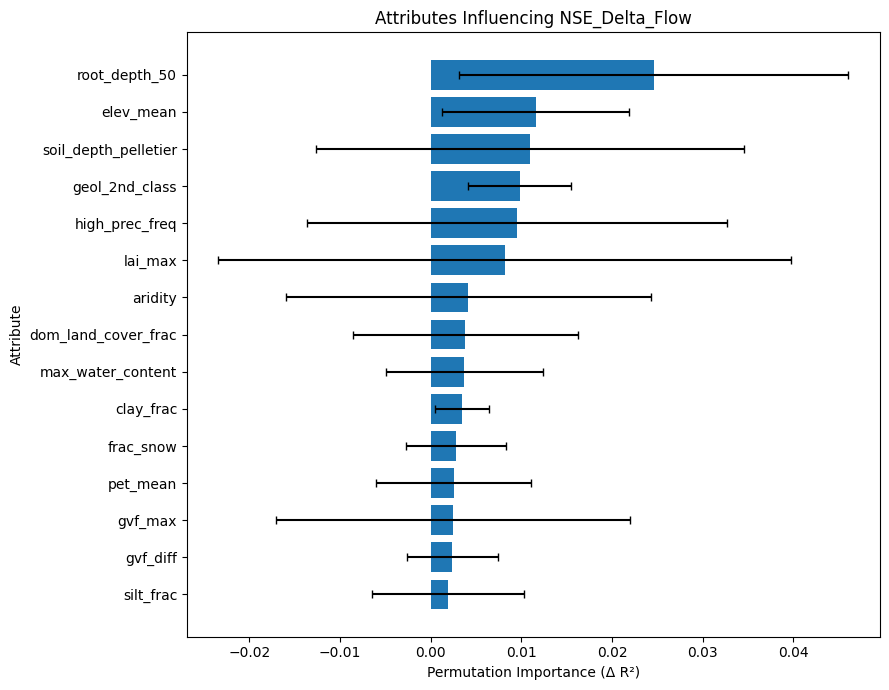

In [37]:
import matplotlib.pyplot as plt

top_n = 15

plot_df = (
    importance_summary
    .head(top_n)
    .sort_values("Mean_Importance")
)

plt.figure(figsize=(9, 7))

plt.barh(
    plot_df.index,
    plot_df["Mean_Importance"],
    xerr=plot_df["SD_Importance"],
    capsize=3
)

plt.xlabel("Permutation Importance (Δ R²)")
plt.ylabel("Attribute")
plt.title(f"Attributes Influencing {target}")

plt.tight_layout()
plt.show()

In [38]:
from scipy.stats import spearmanr

corr_results = []

for col in X_clean.columns:

    rho, pval = spearmanr(
        X_clean[col],
        y_clean
    )

    corr_results.append({
        "Attribute": col,
        "Spearman_rho": rho,
        "p_value": pval,
        "Abs_rho": abs(rho)
    })

corr_df = (
    pd.DataFrame(corr_results)
    .sort_values("Abs_rho", ascending=False)
)

display(corr_df.head(15))

,Attribute,Spearman_rho,p_value,Abs_rho
12,frac_forest,-0.139903,0.001229,0.139903
7,low_prec_freq,0.105574,0.014939,0.105574
5,high_prec_freq,0.097940,0.024009,0.097940
0,p_mean,-0.087352,0.044221,0.087352
19,root_depth_50,-0.087172,0.044662,0.087172
14,lai_diff,-0.086129,0.047287,0.086129
4,aridity,0.085725,0.048340,0.085725
32,carbonate_rocks_frac,0.081774,0.059692,0.081774
15,gvf_max,-0.078541,0.070548,0.078541
34,geol_permeability,0.077411,0.074701,0.077411


In [39]:
combined = (
    importance_summary
    .reset_index()
    .merge(
        corr_df[
            ["Attribute", "Spearman_rho", "p_value"]
        ],
        on="Attribute"
    )
)

combined = combined.sort_values(
    "Mean_Importance",
    ascending=False
)

display(combined.head(20))

,Attribute,Mean_Importance,SD_Importance,Spearman_rho,p_value
0,root_depth_50,0.024611,0.021478,-0.087172,0.044662
1,elev_mean,0.011622,0.010314,0.011912,0.784192
2,soil_depth_pelletier,0.010947,0.023569,-0.033472,0.441472
3,geol_2nd_class,0.009820,0.005718,-0.000099,0.998178
4,high_prec_freq,0.009484,0.023155,0.097940,0.024009
5,lai_max,0.008200,0.031603,-0.076635,0.077669
6,aridity,0.004147,0.020139,0.085725,0.048340
7,dom_land_cover_frac,0.003847,0.012423,0.024405,0.574707
8,max_water_content,0.003722,0.008678,-0.009642,0.824576
9,clay_frac,0.003472,0.002960,0.021360,0.623345


In [42]:
import shap

# Fit RF on all available data
rf_final = RandomForestRegressor(
    n_estimators=1000,
    max_features="sqrt",
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_clean, y_clean)

# SHAP
explainer = shap.TreeExplainer(rf_final)

shap_values = explainer.shap_values(X_clean)

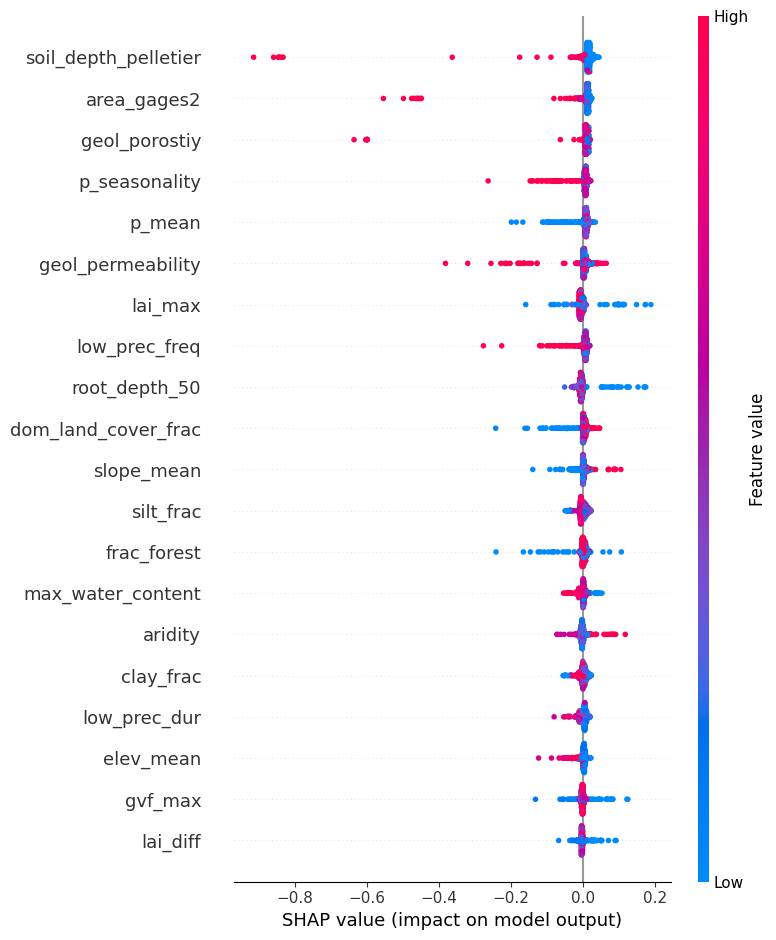

In [43]:
shap.summary_plot(
    shap_values,
    X_clean,
    max_display=20
)

<Figure size 800x600 with 0 Axes>

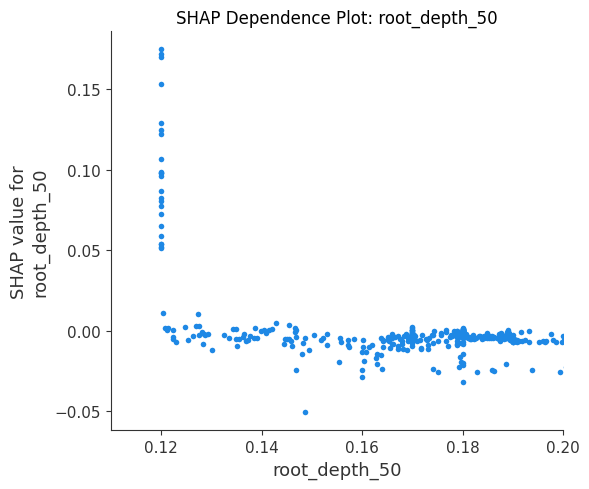

<Figure size 800x600 with 0 Axes>

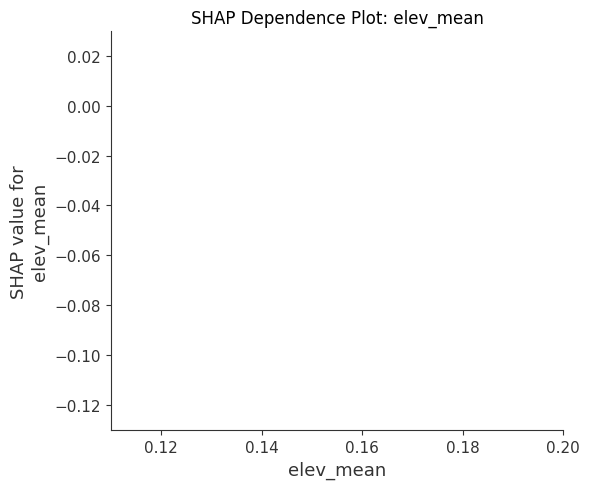

<Figure size 800x600 with 0 Axes>

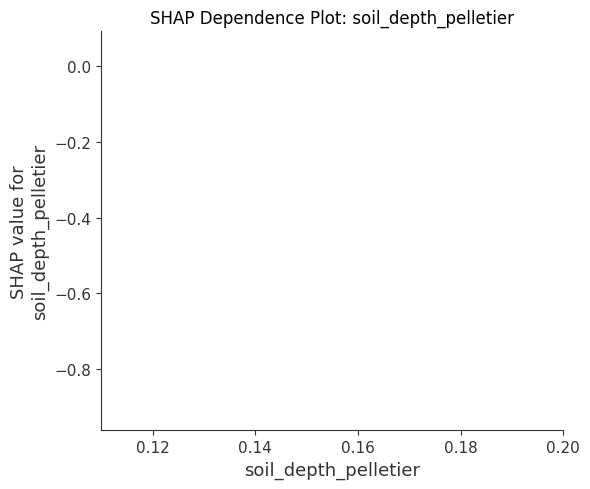

<Figure size 800x600 with 0 Axes>

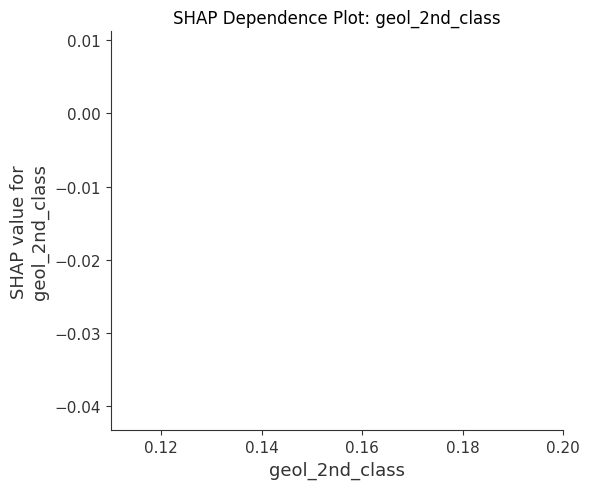

<Figure size 800x600 with 0 Axes>

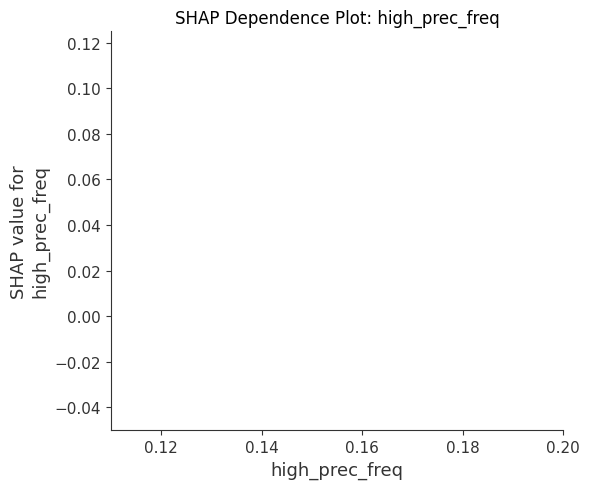

<Figure size 800x600 with 0 Axes>

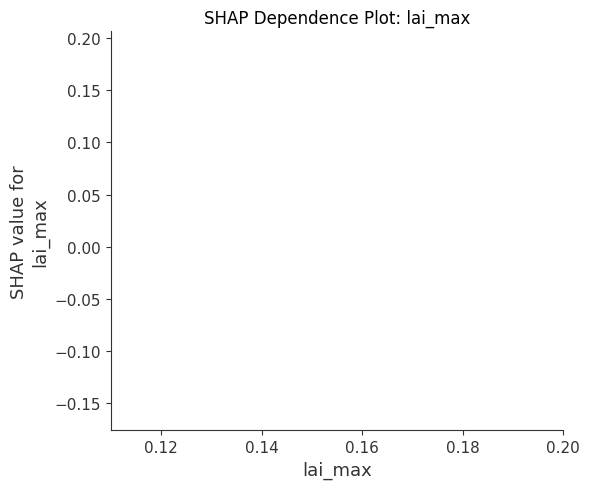

<Figure size 800x600 with 0 Axes>

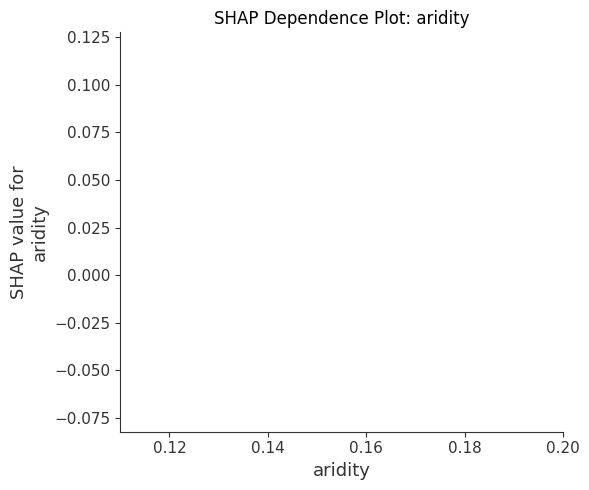

<Figure size 800x600 with 0 Axes>

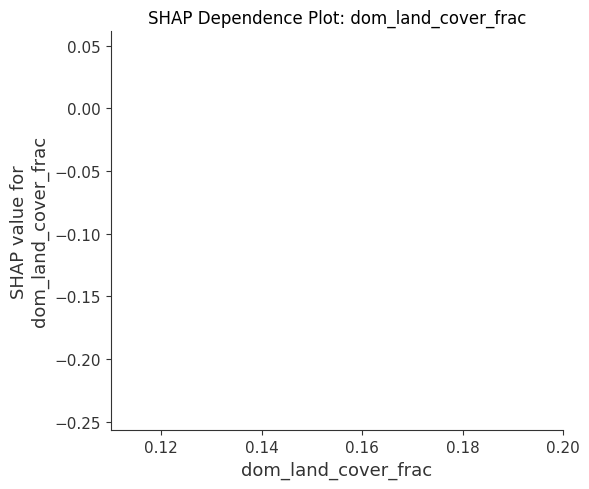

<Figure size 800x600 with 0 Axes>

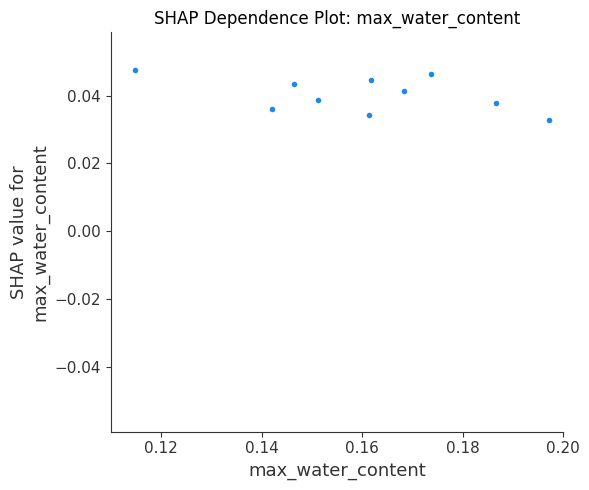

<Figure size 800x600 with 0 Axes>

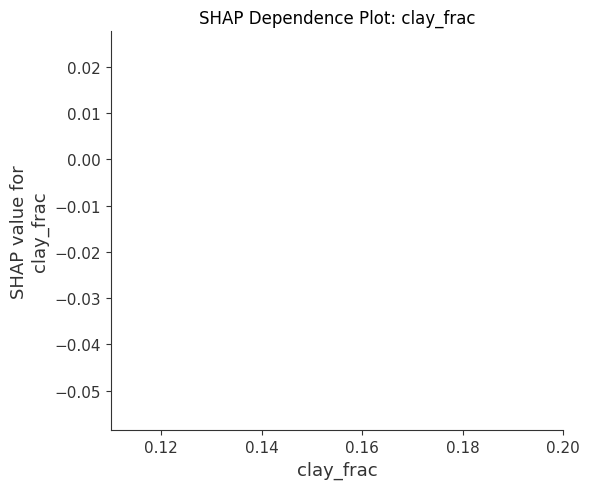

In [58]:
top_attributes = importance_summary.head(10).index

for feature in top_attributes:
    plt.figure(figsize=(8, 6))
    
    # Generate the SHAP dependence plot
    shap.dependence_plot(
        feature,
        shap_values,
        X_clean,
        interaction_index=None,
        show=False  # Prevents SHAP from immediately calling plt.show() so we can customize it
    )
    
    # Apply your custom limits and formatting
    plt.xlim(0.11, 0.2)
    plt.title(f"SHAP Dependence Plot: {feature}")
    plt.tight_layout()
    
    # Optional: Save each plot to a file
    # plt.savefig(f"shap_dependence_{feature}.png", dpi=300)
    
    plt.show()

In [ ]:
# ============================================================
# IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.base import clone


# ============================================================
# SETTINGS
# ============================================================

method = "Eckhardt"
hydromodel = "HBV"

target = "NSE_Delta_Baseflow"

# Correlation threshold
corr_threshold = 0.80


# ============================================================
# READ DATA
# ============================================================

df = pd.read_csv(
    f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/RF/"
    f"RandomForest_{method}_{hydromodel}.csv"
)


# ============================================================
# ATTRIBUTE NAMES
# ============================================================

attrnames = [
    "p_mean",
    "pet_mean",
    "p_seasonality",
    "frac_snow",
    "aridity",
    "high_prec_freq",
    "high_prec_dur",
    "low_prec_freq",
    "low_prec_dur",
    "elev_mean",
    "slope_mean",
    "area_gages2",
    "frac_forest",
    "lai_max",
    "lai_diff",
    "gvf_max",
    "gvf_diff",
    "dom_land_cover_frac",
    "dom_land_cover",
    "root_depth_50",
    "soil_depth_pelletier",
    "soil_depth_statsgo",
    "soil_porosity",
    "soil_conductivity",
    "max_water_content",
    "sand_frac",
    "silt_frac",
    "clay_frac",
    "geol_1st_class",
    "glim_1st_class_frac",
    "geol_2nd_class",
    "glim_2nd_class_frac",
    "carbonate_rocks_frac",
    "geol_porostiy",
    "geol_permeability"
]


# ============================================================
# RENAME ATTRIBUTES
# ============================================================

rename_dict = {
    f"Attr_{i+1}": attrnames[i]
    for i in range(35)
}

df.rename(
    columns=rename_dict,
    inplace=True
)


# ============================================================
# REMOVE NON-PREDICTOR COLUMNS
# ============================================================

columns_to_remove = [
    "Model",
    "Region",
    "GAGE_ID",

    "NSE_Flow_Single",
    "NSE_Flow_Multi",
    "NSE_Baseflow_Single",
    "NSE_Baseflow_Multi",
    "NSE_Delta_Flow"
]

df.drop(
    columns=columns_to_remove,
    inplace=True,
    errors="ignore"
)


# ============================================================
# SELECT THE ATTRIBUTES YOU CURRENTLY WANT TO RETAIN
# ============================================================
#
# These are the variables NOT commented out in your original
# selection.
#
# ============================================================

selected_attributes = attrnames
# [
#     "frac_snow",
#     "aridity",
#     "elev_mean",
#     "slope_mean",
#     "lai_diff",
#     "gvf_diff",
#     "dom_land_cover_frac",
#     "soil_depth_pelletier",
#     "soil_depth_statsgo",
#     "silt_frac",
#     "geol_2nd_class",
#     "glim_2nd_class_frac",
#     "geol_permeability"
# ]


# ============================================================
# CHECK THAT ALL ATTRIBUTES EXIST
# ============================================================

missing_attributes = [
    col for col in selected_attributes
    if col not in df.columns
]

if len(missing_attributes) > 0:

    raise ValueError(
        "The following attributes are missing from the dataframe:\n"
        + "\n".join(missing_attributes)
    )


# ============================================================
# CREATE X AND y
# ============================================================

X = df[selected_attributes].copy()

y = df[target].copy()


# ============================================================
# REMOVE MISSING VALUES
# ============================================================

valid = (
    y.notna()
    &
    X.notna().all(axis=1)
)

X_clean = X.loc[valid].copy()
y_clean = y.loc[valid].copy()

X_clean.reset_index(drop=True, inplace=True)
y_clean.reset_index(drop=True, inplace=True)


print("=" * 70)
print("DATASET")
print("=" * 70)

print("Hydrological model :", hydromodel)
print("Baseflow method    :", method)
print("Target             :", target)

print("Number of basins   :", len(y_clean))
print("Initial predictors :", X_clean.shape[1])

print("\nInitial attributes:")
for col in X_clean.columns:
    print("  ", col)


# ============================================================
# SPEARMAN CORRELATION
# ============================================================

corr = X_clean.corr(
    method="spearman"
)


# Absolute correlation for identifying redundancy
corr_abs = corr.abs()


# ============================================================
# FIND HIGHLY CORRELATED PAIRS
# ============================================================

upper = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)


high_corr_pairs = (
    upper
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Attribute_1",
    "Attribute_2",
    "Abs_Spearman"
]


high_corr_pairs = (
    high_corr_pairs[
        high_corr_pairs["Abs_Spearman"] >= corr_threshold
    ]
    .sort_values(
        "Abs_Spearman",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# DISPLAY CORRELATED PAIRS
# ============================================================

print("\n" + "=" * 70)
print(
    f"HIGHLY CORRELATED PAIRS "
    f"(|Spearman rho| >= {corr_threshold})"
)
print("=" * 70)

if len(high_corr_pairs) == 0:

    print("No highly correlated pairs found.")

else:

    display(high_corr_pairs)


# ============================================================
# CALCULATE UNIVARIATE SPEARMAN RELATIONSHIP WITH TARGET
# ============================================================
#
# For each correlated pair, we will retain the variable that
# has the stronger absolute relationship with the target.
#
# ============================================================

target_corr = {}

for col in X_clean.columns:

    rho, pval = spearmanr(
        X_clean[col],
        y_clean
    )

    target_corr[col] = {
        "rho": rho,
        "abs_rho": abs(rho),
        "p_value": pval
    }


target_corr_df = pd.DataFrame(
    target_corr
).T

target_corr_df.index.name = "Attribute"


# ============================================================
# DETERMINE WHICH ATTRIBUTES TO REMOVE
# ============================================================

to_remove = set()

correlation_decisions = []


for _, row in high_corr_pairs.iterrows():

    attr1 = row["Attribute_1"]
    attr2 = row["Attribute_2"]

    rho1 = target_corr[attr1]["abs_rho"]
    rho2 = target_corr[attr2]["abs_rho"]

    # --------------------------------------------------------
    # Keep the variable more strongly associated with target
    # --------------------------------------------------------

    if rho1 >= rho2:

        keep = attr1
        remove = attr2

    else:

        keep = attr2
        remove = attr1

    # --------------------------------------------------------
    # Store decision
    # --------------------------------------------------------

    correlation_decisions.append({

        "Attribute_1": attr1,

        "Attribute_2": attr2,

        "Abs_Spearman_Between":
            row["Abs_Spearman"],

        "Abs_Spearman_Target_1":
            rho1,

        "Abs_Spearman_Target_2":
            rho2,

        "Keep":
            keep,

        "Remove":
            remove
    })


    to_remove.add(remove)


correlation_decisions = pd.DataFrame(
    correlation_decisions
)


# ============================================================
# IMPORTANT:
# A variable may be correlated with multiple variables.
#
# Therefore, after the initial removal, check again and retain
# the final non-redundant set.
# ============================================================

X_reduced = X_clean.drop(
    columns=list(to_remove),
    errors="ignore"
)


# ============================================================
# FINAL CORRELATION CHECK
# ============================================================

final_corr = X_reduced.corr(
    method="spearman"
).abs()

final_upper = final_corr.where(
    np.triu(
        np.ones(final_corr.shape),
        k=1
    ).astype(bool)
)

remaining_high_corr = (
    final_upper
    .stack()
    .reset_index()
)

remaining_high_corr.columns = [
    "Attribute_1",
    "Attribute_2",
    "Abs_Spearman"
]

remaining_high_corr = (
    remaining_high_corr[
        remaining_high_corr["Abs_Spearman"]
        >= corr_threshold
    ]
    .sort_values(
        "Abs_Spearman",
        ascending=False
    )
)


# ============================================================
# DISPLAY REDUCTION RESULTS
# ============================================================

print("\n" + "=" * 70)
print("CORRELATION-BASED FEATURE REDUCTION")
print("=" * 70)

print("\nRemoved attributes:")

if len(to_remove) == 0:

    print("None")

else:

    for col in sorted(to_remove):
        print("  ", col)


print("\nRemaining attributes:")

for col in X_reduced.columns:
    print("  ", col)


print(
    "\nNumber of predictors before:",
    X_clean.shape[1]
)

print(
    "Number of predictors after :",
    X_reduced.shape[1]
)


# ============================================================
# DISPLAY DECISIONS
# ============================================================

if len(correlation_decisions) > 0:

    print("\n" + "=" * 70)
    print("CORRELATION DECISIONS")
    print("=" * 70)

    display(correlation_decisions)


# ============================================================
# FINAL CORRELATION CHECK
# ============================================================

print("\n" + "=" * 70)
print("FINAL CORRELATION CHECK")
print("=" * 70)

if len(remaining_high_corr) == 0:

    print(
        f"No remaining predictor pairs with "
        f"|Spearman rho| >= {corr_threshold}"
    )

else:

    print(
        "Remaining highly correlated pairs:"
    )

    display(remaining_high_corr)


# ============================================================
# RANDOM FOREST
# ============================================================

rf = RandomForestRegressor(
    n_estimators=1000,
    max_features="sqrt",
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)


# ============================================================
# 5-FOLD CROSS VALIDATION
# ============================================================

kf = KFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)


# ============================================================
# CONTAINERS
# ============================================================

importance_results = []

fold_r2_results = []
fold_rmse_results = []

oof_predictions = np.full(
    len(y_clean),
    np.nan
)


# ============================================================
# CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    kf.split(X_reduced),
    start=1
):

    # --------------------------------------------------------
    # Train / test
    # --------------------------------------------------------

    X_train = X_reduced.iloc[train_idx]
    X_test = X_reduced.iloc[test_idx]

    y_train = y_clean.iloc[train_idx]
    y_test = y_clean.iloc[test_idx]


    # --------------------------------------------------------
    # Fit model
    # --------------------------------------------------------

    model = clone(rf)

    model.fit(
        X_train,
        y_train
    )


    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test
    )


    # --------------------------------------------------------
    # Store OOF prediction
    # --------------------------------------------------------

    oof_predictions[test_idx] = y_pred


    # --------------------------------------------------------
    # R²
    # --------------------------------------------------------

    fold_r2 = r2_score(
        y_test,
        y_pred
    )

    fold_r2_results.append(
        fold_r2
    )


    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    fold_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    fold_rmse_results.append(
        fold_rmse
    )


    print(
        f"Fold {fold}: "
        f"R² = {fold_r2:.4f}, "
        f"RMSE = {fold_rmse:.4f}"
    )


    # ========================================================
    # PERMUTATION IMPORTANCE
    # ========================================================

    perm = permutation_importance(
        model,
        X_test,
        y_test,
        n_repeats=30,
        random_state=42,
        scoring="r2",
        n_jobs=-1
    )


    fold_df = pd.DataFrame({

        "Attribute":
            X_reduced.columns,

        "Importance":
            perm.importances_mean,

        "Within_Fold_SD":
            perm.importances_std,

        "Fold":
            fold

    })


    importance_results.append(
        fold_df
    )


# ============================================================
# OOF PERFORMANCE
# ============================================================

fold_r2_results = np.array(
    fold_r2_results
)

fold_rmse_results = np.array(
    fold_rmse_results
)


oof_r2 = r2_score(
    y_clean,
    oof_predictions
)


oof_rmse = np.sqrt(
    mean_squared_error(
        y_clean,
        oof_predictions
    )
)


# ============================================================
# PERFORMANCE SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("RANDOM FOREST PERFORMANCE")
print("=" * 70)

for i in range(5):

    print(
        f"Fold {i+1}: "
        f"R² = {fold_r2_results[i]:.4f}, "
        f"RMSE = {fold_rmse_results[i]:.4f}"
    )


print("-" * 70)

print(
    f"Mean Fold R²   = "
    f"{fold_r2_results.mean():.4f}"
)

print(
    f"SD Fold R²     = "
    f"{fold_r2_results.std(ddof=1):.4f}"
)

print(
    f"Mean Fold RMSE = "
    f"{fold_rmse_results.mean():.4f}"
)

print(
    f"SD Fold RMSE   = "
    f"{fold_rmse_results.std(ddof=1):.4f}"
)

print("-" * 70)

print(
    f"Overall OOF R²   = "
    f"{oof_r2:.4f}"
)

print(
    f"Overall OOF RMSE = "
    f"{oof_rmse:.4f}"
)

print("=" * 70)


# ============================================================
# PERMUTATION IMPORTANCE SUMMARY
# ============================================================

importance_df = pd.concat(
    importance_results,
    ignore_index=True
)


importance_summary = (
    importance_df
    .groupby("Attribute")
    .agg(
        Mean_Importance=(
            "Importance",
            "mean"
        ),

        SD_Importance=(
            "Importance",
            "std"
        )
    )
    .sort_values(
        "Mean_Importance",
        ascending=False
    )
)


# ============================================================
# DISPLAY FINAL IMPORTANCE
# ============================================================

print("\n" + "=" * 70)
print("PERMUTATION IMPORTANCE")
print("=" * 70)

display(
    importance_summary
)


# ============================================================
# FINAL OOF DATAFRAME
# ============================================================

oof_df = pd.DataFrame({

    "Observed_NSE_Delta_Baseflow":
        y_clean,

    "Predicted_NSE_Delta_Baseflow":
        oof_predictions

})


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)

print(
    f"Model              : {hydromodel}"
)

print(
    f"Baseflow method    : {method}"
)

print(
    f"Target             : {target}"
)

print(
    f"Basins             : {len(y_clean)}"
)

print(
    f"Predictors before  : {X_clean.shape[1]}"
)

print(
    f"Predictors after   : {X_reduced.shape[1]}"
)

print(
    f"Overall OOF R²     : {oof_r2:.4f}"
)

print(
    f"Overall OOF RMSE   : {oof_rmse:.4f}"
)

print("=" * 70)

In [ ]:
import pandas as pd